In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("zomato.csv")

# DATA PREVIEW

In [3]:
df.head()

,url,address,name,online_order,book_table,rate,votes,phone,location,rest_type,dish_liked,cuisines,approx_cost(for two people),reviews_list,menu_item,listed_in(type),listed_in(city)
0,https://www.zomato.com/bangalore/jalsa-banasha...,"942, 21st Main Road, 2nd Stage, Banashankari, ...",Jalsa,Yes,Yes,4.1/5,775,080 42297555\r\n+91 9743772233,Banashankari,Casual Dining,"Pasta, Lunch Buffet, Masala Papad, Paneer Laja...","North Indian, Mughlai, Chinese",800,"[('Rated 4.0', 'RATED\n A beautiful place to ...",[],Buffet,Banashankari
1,https://www.zomato.com/bangalore/spice-elephan...,"2nd Floor, 80 Feet Road, Near Big Bazaar, 6th ...",Spice Elephant,Yes,No,4.1/5,787,080 41714161,Banashankari,Casual Dining,"Momos, Lunch Buffet, Chocolate Nirvana, Thai G...","Chinese, North Indian, Thai",800,"[('Rated 4.0', 'RATED\n Had been here for din...",[],Buffet,Banashankari
2,https://www.zomato.com/SanchurroBangalore?cont...,"1112, Next to KIMS Medical College, 17th Cross...",San Churro Cafe,Yes,No,3.8/5,918,+91 9663487993,Banashankari,"Cafe, Casual Dining","Churros, Cannelloni, Minestrone Soup, Hot Choc...","Cafe, Mexican, Italian",800,"[('Rated 3.0', ""RATED\n Ambience is not that ...",[],Buffet,Banashankari
3,https://www.zomato.com/bangalore/addhuri-udupi...,"1st Floor, Annakuteera, 3rd Stage, Banashankar...",Addhuri Udupi Bhojana,No,No,3.7/5,88,+91 9620009302,Banashankari,Quick Bites,Masala Dosa,"South Indian, North Indian",300,"[('Rated 4.0', ""RATED\n Great food and proper...",[],Buffet,Banashankari
4,https://www.zomato.com/bangalore/grand-village...,"10, 3rd Floor, Lakshmi Associates, Gandhi Baza...",Grand Village,No,No,3.8/5,166,+91 8026612447\r\n+91 9901210005,Basavanagudi,Casual Dining,"Panipuri, Gol Gappe","North Indian, Rajasthani",600,"[('Rated 4.0', 'RATED\n Very good restaurant ...",[],Buffet,Banashankari


In [4]:
df.shape

(51717, 17)

In [5]:
df.columns

Index(['url', 'address', 'name', 'online_order', 'book_table', 'rate', 'votes',
       'phone', 'location', 'rest_type', 'dish_liked', 'cuisines',
       'approx_cost(for two people)', 'reviews_list', 'menu_item',
       'listed_in(type)', 'listed_in(city)'],
      dtype='str')

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 51717 entries, 0 to 51716
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   url                          51717 non-null  str  
 1   address                      51717 non-null  str  
 2   name                         51717 non-null  str  
 3   online_order                 51717 non-null  str  
 4   book_table                   51717 non-null  str  
 5   rate                         43942 non-null  str  
 6   votes                        51717 non-null  int64
 7   phone                        50509 non-null  str  
 8   location                     51696 non-null  str  
 9   rest_type                    51490 non-null  str  
 10  dish_liked                   23639 non-null  str  
 11  cuisines                     51672 non-null  str  
 12  approx_cost(for two people)  51371 non-null  str  
 13  reviews_list                 51717 non-null  str  
 14  m

In [7]:
df.describe()

,votes
count,51717.000000
mean,283.697527
std,803.838853
min,0.000000
25%,7.000000
50%,41.000000
75%,198.000000
max,16832.000000


# DATA CLEANING

In [8]:
df.isnull().sum()

url                                0
address                            0
name                               0
online_order                       0
book_table                         0
rate                            7775
votes                              0
phone                           1208
location                          21
rest_type                        227
dish_liked                     28078
cuisines                          45
approx_cost(for two people)      346
reviews_list                       0
menu_item                          0
listed_in(type)                    0
listed_in(city)                    0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
(df.isnull().sum() / len(df)) * 100                           #checking percentage of missing vaues

url                             0.000000
address                         0.000000
name                            0.000000
online_order                    0.000000
book_table                      0.000000
rate                           15.033741
votes                           0.000000
phone                           2.335789
location                        0.040606
rest_type                       0.438927
dish_liked                     54.291626
cuisines                        0.087012
approx_cost(for two people)     0.669026
reviews_list                    0.000000
menu_item                       0.000000
listed_in(type)                 0.000000
listed_in(city)                 0.000000
dtype: float64

In [11]:
df_clean = df.copy()

In [12]:
df_clean.drop(                                            #drop unnecessary columns
    columns=['url', 'address', 'phone', 'dish_liked'],
    inplace=True
)

In [13]:
df_clean.dropna(                                           #Remove rows with missing important values
    subset=['location', 'rest_type', 'cuisines',
            'approx_cost(for two people)'],
    inplace=True
)

In [14]:
df_clean.shape

(51148, 13)

In [15]:
df_clean.isnull().sum()

name                              0
online_order                      0
book_table                        0
rate                           7615
votes                             0
location                          0
rest_type                         0
cuisines                          0
approx_cost(for two people)       0
reviews_list                      0
menu_item                         0
listed_in(type)                   0
listed_in(city)                   0
dtype: int64

In [16]:
df_clean.info()

<class 'pandas.DataFrame'>
Index: 51148 entries, 0 to 51716
Data columns (total 13 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   name                         51148 non-null  str  
 1   online_order                 51148 non-null  str  
 2   book_table                   51148 non-null  str  
 3   rate                         43533 non-null  str  
 4   votes                        51148 non-null  int64
 5   location                     51148 non-null  str  
 6   rest_type                    51148 non-null  str  
 7   cuisines                     51148 non-null  str  
 8   approx_cost(for two people)  51148 non-null  str  
 9   reviews_list                 51148 non-null  str  
 10  menu_item                    51148 non-null  str  
 11  listed_in(type)              51148 non-null  str  
 12  listed_in(city)              51148 non-null  str  
dtypes: int64(1), str(12)
memory usage: 521.6 MB


In [17]:
df_clean['rate'].unique()

<ArrowStringArray>
[ '4.1/5',  '3.8/5',  '3.7/5',  '3.6/5',  '4.6/5',  '4.0/5',  '4.2/5',
  '3.9/5',  '3.1/5',  '3.0/5',  '3.2/5',  '3.3/5',  '2.8/5',  '4.4/5',
  '4.3/5',    'NEW',  '2.9/5',  '3.5/5',      nan,  '2.6/5', '3.8 /5',
  '3.4/5',  '4.5/5',  '2.5/5',  '2.7/5',  '4.7/5',  '2.4/5',  '2.2/5',
  '2.3/5', '3.4 /5',      '-', '3.6 /5',  '4.8/5', '3.9 /5', '4.2 /5',
 '4.0 /5', '4.1 /5', '3.7 /5', '3.1 /5', '2.9 /5', '3.3 /5', '2.8 /5',
 '3.5 /5', '2.7 /5', '2.5 /5', '3.2 /5', '2.6 /5', '4.5 /5', '4.3 /5',
 '4.4 /5',  '4.9/5',  '2.1/5',  '2.0/5',  '1.8/5', '4.6 /5', '4.9 /5',
 '3.0 /5', '4.8 /5', '2.3 /5', '4.7 /5', '2.4 /5', '2.1 /5', '2.2 /5',
 '2.0 /5', '1.8 /5']
Length: 65, dtype: str

In [18]:
df_clean['rate'].dtype

<StringDtype(na_value=nan)>

In [19]:
df_clean.shape

(51148, 13)

In [20]:
df_clean['rate'] = df_clean['rate'].str.replace('/5', '', regex=False)

In [21]:
df_clean['rate'] = df_clean['rate'].str.strip()

In [22]:
df_clean['rate'] = df_clean['rate'].replace(['NEW', '-'], np.nan)

In [23]:
df_clean['rate'] = pd.to_numeric(df_clean['rate'])

In [24]:
df_clean['rate'].dtype

dtype('float64')

In [25]:
df_clean['rate'].unique()

array([4.1, 3.8, 3.7, 3.6, 4.6, 4. , 4.2, 3.9, 3.1, 3. , 3.2, 3.3, 2.8,
       4.4, 4.3, nan, 2.9, 3.5, 2.6, 3.4, 4.5, 2.5, 2.7, 4.7, 2.4, 2.2,
       2.3, 4.8, 4.9, 2.1, 2. , 1.8])

In [26]:
df_clean['rate'].isnull().sum()

np.int64(9885)

In [27]:
df_clean['rate'].describe()

count    41263.000000
mean         3.702011
std          0.439985
min          1.800000
25%          3.400000
50%          3.700000
75%          4.000000
max          4.900000
Name: rate, dtype: float64

In [28]:
df_clean['approx_cost(for two people)'].unique()

<ArrowStringArray>
[  '800',   '300',   '600',   '700',   '550',   '500',   '450',   '650',
   '400',   '900',   '200',   '750',   '150',   '850',   '100', '1,200',
   '350',   '250',   '950', '1,000', '1,500', '1,300',   '199',    '80',
 '1,100',   '160', '1,600',   '230',   '130',    '50',   '190', '1,700',
 '1,400',   '180', '1,350', '2,200', '2,000', '1,800', '1,900',   '330',
 '2,500', '2,100', '3,000', '2,800', '3,400',    '40', '1,250', '3,500',
 '4,000', '2,400', '2,600',   '120', '1,450',   '469',    '70', '3,200',
    '60',   '560',   '240',   '360', '6,000', '1,050', '2,300', '4,100',
 '5,000', '3,700', '1,650', '2,700', '4,500',   '140']
Length: 70, dtype: str

In [29]:
df_clean['approx_cost(for two people)'].dtype

<StringDtype(na_value=nan)>

In [30]:
df_clean['approx_cost(for two people)'] = (
    df_clean['approx_cost(for two people)']
    .str.replace(',', '', regex=False)
)

In [31]:
df_clean['approx_cost(for two people)'] = pd.to_numeric(
    df_clean['approx_cost(for two people)'],
    errors='coerce'
)

In [32]:
df_clean['approx_cost(for two people)'].dtype

dtype('int64')

In [33]:
df_clean['approx_cost(for two people)'].isnull().sum()

np.int64(0)

In [34]:
df_clean['approx_cost(for two people)'].describe()

count    51148.000000
mean       556.043736
std        439.555299
min         40.000000
25%        300.000000
50%        400.000000
75%        700.000000
max       6000.000000
Name: approx_cost(for two people), dtype: float64

In [35]:
df_clean[['rate', 'approx_cost(for two people)']].head(10)

,rate,approx_cost(for two people)
0,4.1,800
1,4.1,800
2,3.8,800
3,3.7,300
4,3.8,600
5,3.8,600
6,3.6,800
7,4.6,600
8,4.0,700
9,4.2,550


# EDA

In [36]:
# Top 10 locations having the highest number of restaurants?

In [37]:
location_count = df_clean['location'].value_counts()

print(location_count.head(10))

location
BTM                      5071
HSR                      2496
Koramangala 5th Block    2481
JP Nagar                 2219
Whitefield               2109
Indiranagar              2033
Jayanagar                1916
Marathahalli             1808
Bannerghatta Road        1611
Bellandur                1271
Name: count, dtype: int64


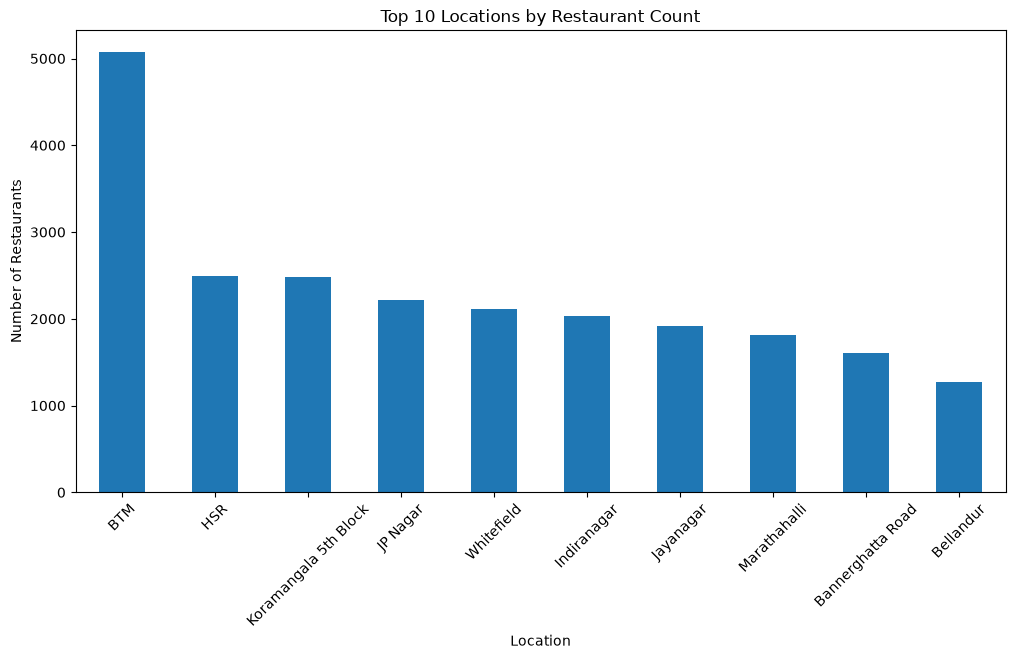

In [38]:
plt.figure(figsize=(12,6))

location_count.head(10).plot(kind='bar')

plt.title('Top 10 Locations by Restaurant Count')
plt.xlabel('Location')
plt.ylabel('Number of Restaurants')
plt.xticks(rotation=45)

plt.show()

In [39]:
location_count.head(10)

location
BTM                      5071
HSR                      2496
Koramangala 5th Block    2481
JP Nagar                 2219
Whitefield               2109
Indiranagar              2033
Jayanagar                1916
Marathahalli             1808
Bannerghatta Road        1611
Bellandur                1271
Name: count, dtype: int64

In [40]:
#Most popular cuisines

In [41]:
cuisine_count = (
    df_clean['cuisines']
    .str.split(',')
    .explode()
    .str.strip()
    .value_counts()
)

print(cuisine_count.head(10))

cuisines
North Indian    20841
Chinese         15368
South Indian     8572
Fast Food        8039
Biryani          6428
Continental      5716
Desserts         5585
Cafe             5251
Beverages        4686
Italian          3353
Name: count, dtype: int64


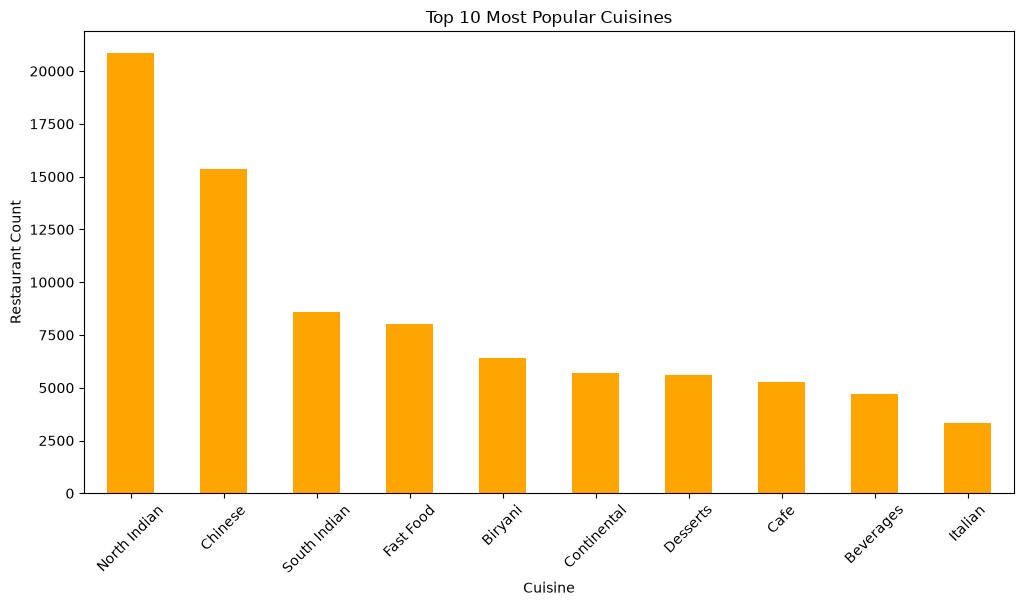

In [42]:
plt.figure(figsize=(12,6))

cuisine_count.head(10).plot(kind='bar', color='orange')

plt.title('Top 10 Most Popular Cuisines')
plt.xlabel('Cuisine')
plt.ylabel('Restaurant Count')
plt.xticks(rotation=45)

plt.show()

In [43]:
# Online Order Analysis

In [44]:
online_count = df_clean['online_order'].value_counts()

print(online_count)

online_order
Yes    30311
No     20837
Name: count, dtype: int64


In [45]:
online_percentage = (
    df_clean['online_order']
    .value_counts(normalize=True) * 100
)

print(online_percentage)

online_order
Yes    59.261359
No     40.738641
Name: proportion, dtype: float64


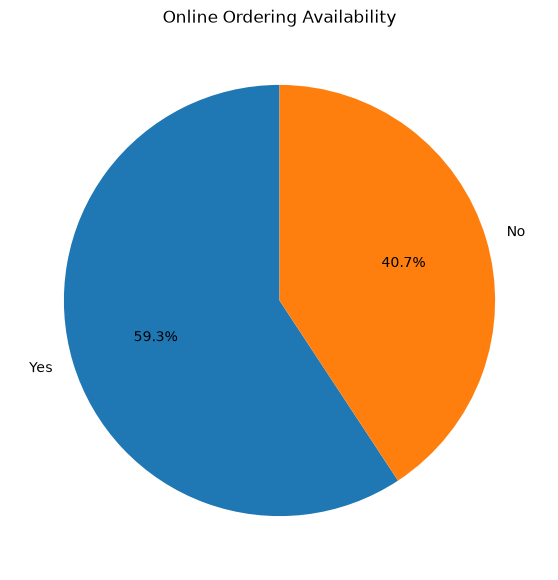

In [46]:
plt.figure(figsize=(7,7))

online_count.plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Online Ordering Availability')
plt.ylabel('')

plt.show()

In [47]:
#Table Booking Analysis.

In [48]:
table_count = df_clean['book_table'].value_counts()

print(table_count)

book_table
No     44699
Yes     6449
Name: count, dtype: int64


In [49]:
table_percentage = (
    df_clean['book_table']
    .value_counts(normalize=True) * 100
)

print(table_percentage)

book_table
No     87.391491
Yes    12.608509
Name: proportion, dtype: float64


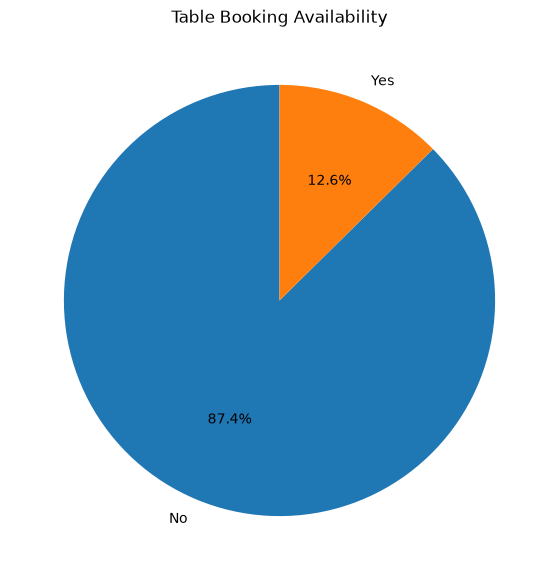

In [50]:
plt.figure(figsize=(7,7))

table_count.plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Table Booking Availability')
plt.ylabel('')

plt.show()

In [51]:
print("Average Rating:", df_clean['rate'].mean())
print("Median Rating:", df_clean['rate'].median())
print("Most Common Rating:", df_clean['rate'].mode()[0])

Average Rating: 3.7020114872888548
Median Rating: 3.7
Most Common Rating: 3.9


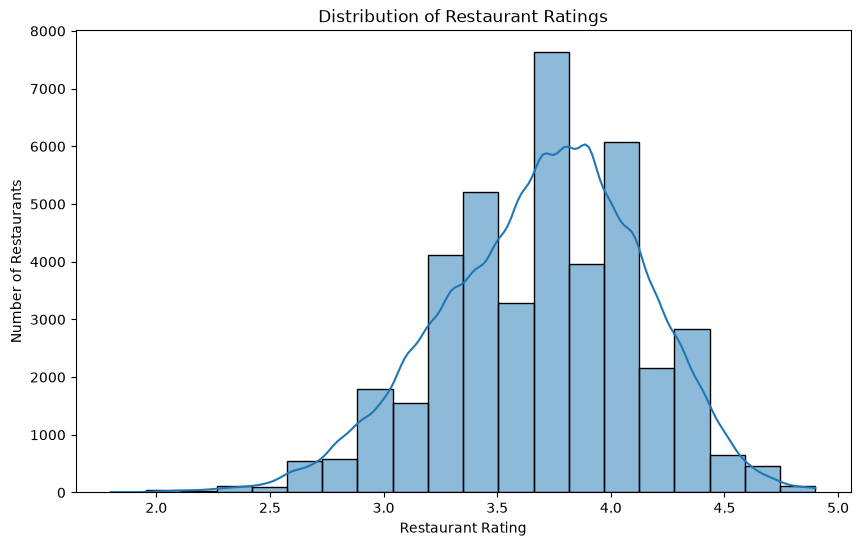

In [52]:
plt.figure(figsize=(10,6))

sns.histplot(
    df_clean['rate'].dropna(),
    bins=20,
    kde=True
)

plt.title('Distribution of Restaurant Ratings')
plt.xlabel('Restaurant Rating')
plt.ylabel('Number of Restaurants')

plt.show()

In [53]:
#Average Cost Analysis

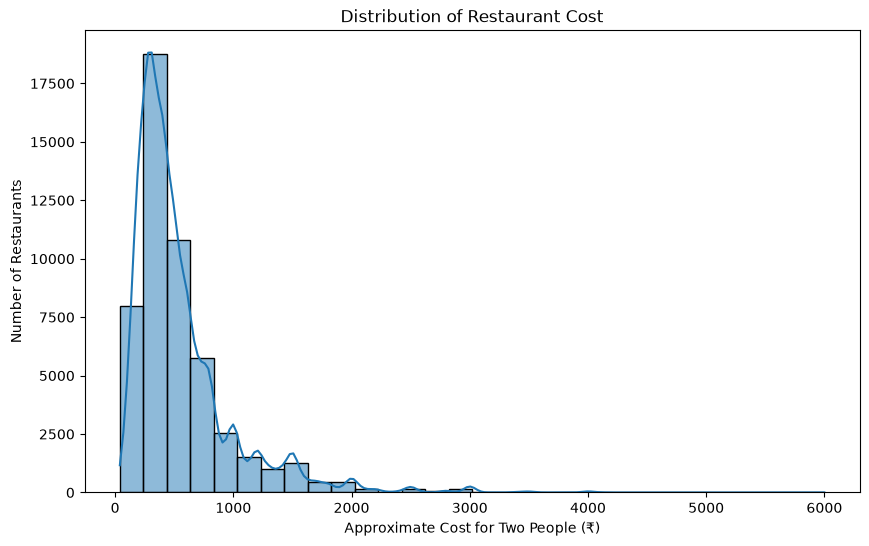

In [54]:
plt.figure(figsize=(10,6))

sns.histplot(
    df_clean['approx_cost(for two people)'],
    bins=30,
    kde=True
)

plt.title('Distribution of Restaurant Cost')
plt.xlabel('Approximate Cost for Two People (₹)')
plt.ylabel('Number of Restaurants')

plt.show()

In [55]:
print(df_clean['approx_cost(for two people)'].describe())

count    51148.000000
mean       556.043736
std        439.555299
min         40.000000
25%        300.000000
50%        400.000000
75%        700.000000
max       6000.000000
Name: approx_cost(for two people), dtype: float64


In [56]:
def cost_category(cost):
    if cost <= 500:
        return 'Budget'
    elif cost <= 1000:
        return 'Mid-range'
    else:
        return 'Expensive'

df_clean['cost_category'] = (
    df_clean['approx_cost(for two people)']
    .apply(cost_category)
)

print(df_clean['cost_category'].value_counts())

cost_category
Budget       33106
Mid-range    12762
Expensive     5280
Name: count, dtype: int64


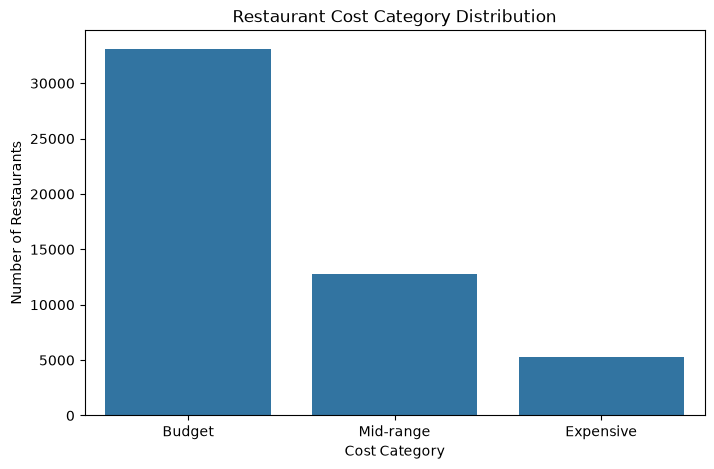

In [57]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df_clean,
    x='cost_category',
    order=['Budget', 'Mid-range', 'Expensive']
)

plt.title('Restaurant Cost Category Distribution')
plt.xlabel('Cost Category')
plt.ylabel('Number of Restaurants')

plt.show()

In [58]:
# Location vs Average Rating

In [59]:
location_rating = (
    df_clean.groupby('location')['rate']
    .mean()
    .sort_values(ascending=False)
)

print(location_rating.head(10))

location
Lavelle Road             4.141788
Koramangala 3rd Block    4.020419
St. Marks Road           4.017201
Koramangala 5th Block    4.006661
Church Street            3.992125
Sankey Road              3.965385
Koramangala 4th Block    3.918668
Cunningham Road          3.901053
Residency Road           3.864570
Koramangala 7th Block    3.852986
Name: rate, dtype: float64


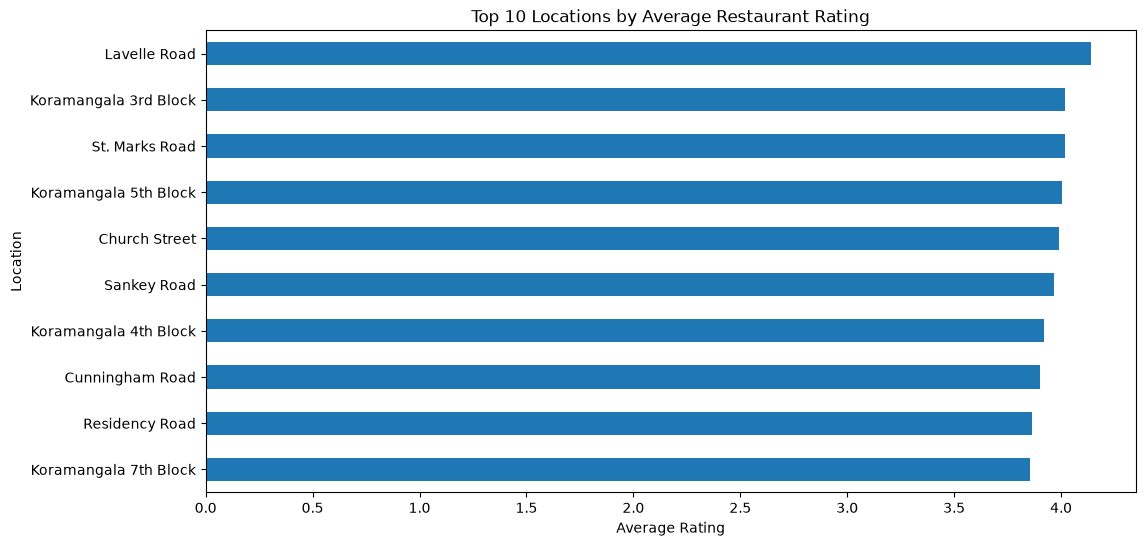

In [62]:
plt.figure(figsize=(12,6))

location_rating.head(10).sort_values().plot(
    kind='barh'
)

plt.title('Top 10 Locations by Average Restaurant Rating')
plt.xlabel('Average Rating')
plt.ylabel('Location')

plt.show()

In [63]:
# Location-wise Restaurant Count vs Rating

In [64]:
location_analysis = df_clean.groupby('location').agg(
    restaurant_count=('name', 'count'),
    average_rating=('rate', 'mean')
)

print(location_analysis.head(10))

                    restaurant_count  average_rating
location                                            
BTM                             5071        3.571410
Banashankari                     904        3.649866
Banaswadi                        645        3.496368
Bannerghatta Road               1611        3.509869
Basavanagudi                     684        3.671092
Basaveshwara Nagar               187        3.649624
Bellandur                       1271        3.531394
Bommanahalli                     236        3.190972
Brigade Road                    1218        3.705228
Brookefield                      656        3.599632


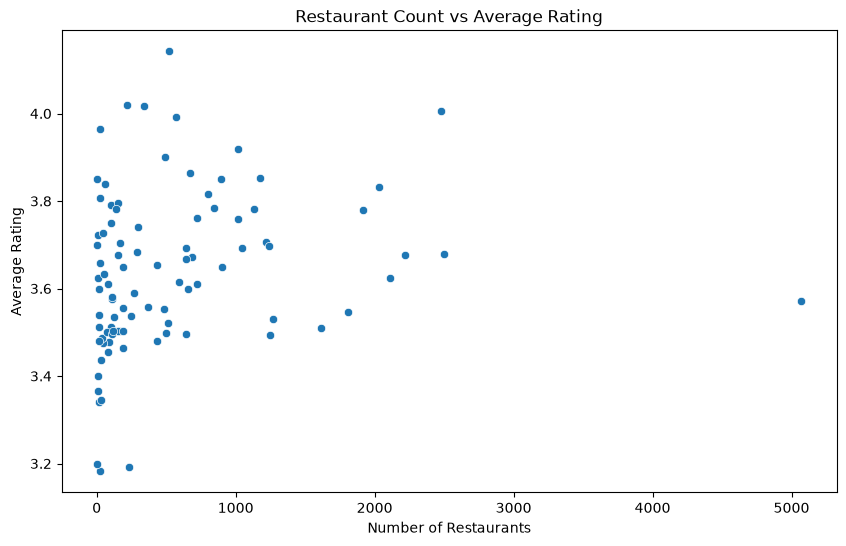

In [65]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=location_analysis,
    x='restaurant_count',
    y='average_rating'
)

plt.title('Restaurant Count vs Average Rating')
plt.xlabel('Number of Restaurants')
plt.ylabel('Average Rating')

plt.show()

In [66]:
correlation = location_analysis[
    ['restaurant_count', 'average_rating']
].corr()

print(correlation)

                  restaurant_count  average_rating
restaurant_count          1.000000        0.208779
average_rating            0.208779        1.000000


In [67]:
# Online Order vs Restaurant Rating

In [68]:
online_rating = df_clean.groupby('online_order')['rate'].mean()

print(online_rating)

online_order
No     3.660031
Yes    3.723947
Name: rate, dtype: float64


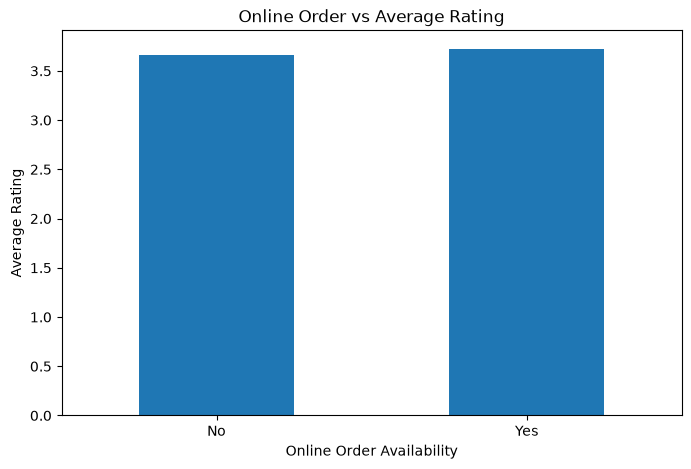

In [69]:
plt.figure(figsize=(8,5))

online_rating.plot(kind='bar')

plt.title('Online Order vs Average Rating')
plt.xlabel('Online Order Availability')
plt.ylabel('Average Rating')
plt.xticks(rotation=0)

plt.show()

In [70]:
# Table Booking vs Average Rating

In [71]:
table_rating = df_clean.groupby('book_table')['rate'].mean()

print(table_rating)

book_table
No     3.622406
Yes    4.143464
Name: rate, dtype: float64


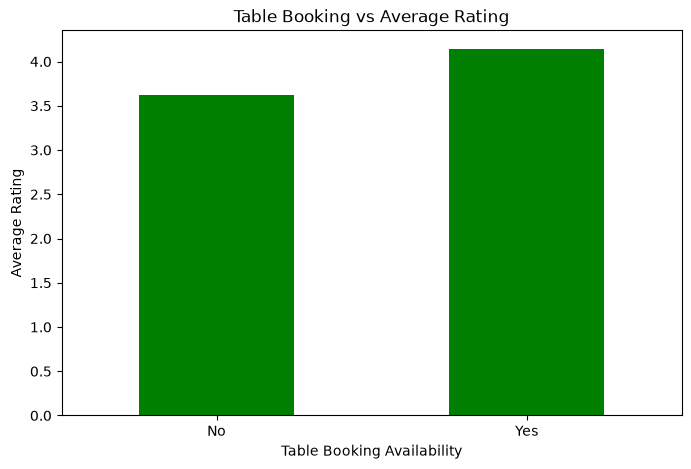

In [72]:
plt.figure(figsize=(8,5))

table_rating.plot(kind='bar', color='green')

plt.title('Table Booking vs Average Rating')
plt.xlabel('Table Booking Availability')
plt.ylabel('Average Rating')
plt.xticks(rotation=0)

plt.show()

In [73]:
# Type vs Average Rating

In [74]:
rest_type_rating = (
    df_clean.groupby('rest_type')['rate']
    .mean()
    .sort_values(ascending=False)
)

print(rest_type_rating.head(10))

rest_type
Pub, Cafe                      4.657500
Bar, Pub                       4.600000
Microbrewery                   4.478571
Pub, Microbrewery              4.452632
Microbrewery, Bar              4.446154
Microbrewery, Pub              4.438095
Casual Dining, Irani Cafee     4.406667
Cafe, Lounge                   4.400000
Fine Dining, Lounge            4.400000
Microbrewery, Casual Dining    4.369421
Name: rate, dtype: float64


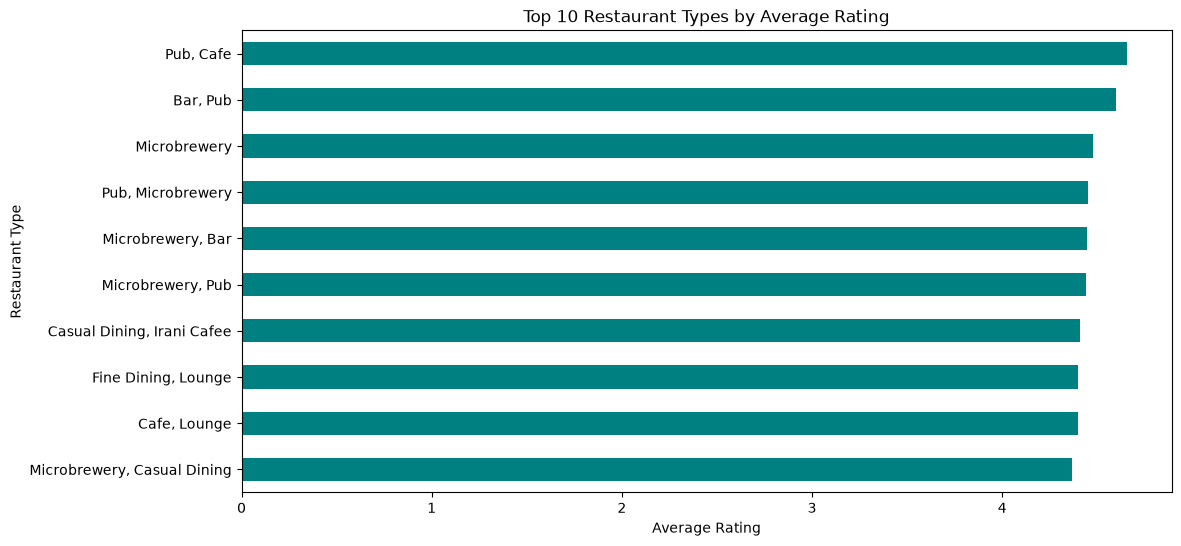

In [75]:
plt.figure(figsize=(12,6))

rest_type_rating.head(10).sort_values().plot(
    kind='barh',
    color='teal'
)

plt.title('Top 10 Restaurant Types by Average Rating')
plt.xlabel('Average Rating')
plt.ylabel('Restaurant Type')

plt.show()

In [76]:
# Most Popular Restaurant Types

In [77]:
rest_type_count = df_clean['rest_type'].value_counts()

print(rest_type_count.head(10))

rest_type
Quick Bites           19046
Casual Dining         10273
Cafe                   3687
Delivery               2578
Dessert Parlor         2245
Takeaway, Delivery     2014
Bakery                 1141
Casual Dining, Bar     1136
Beverage Shop           865
Bar                     686
Name: count, dtype: int64


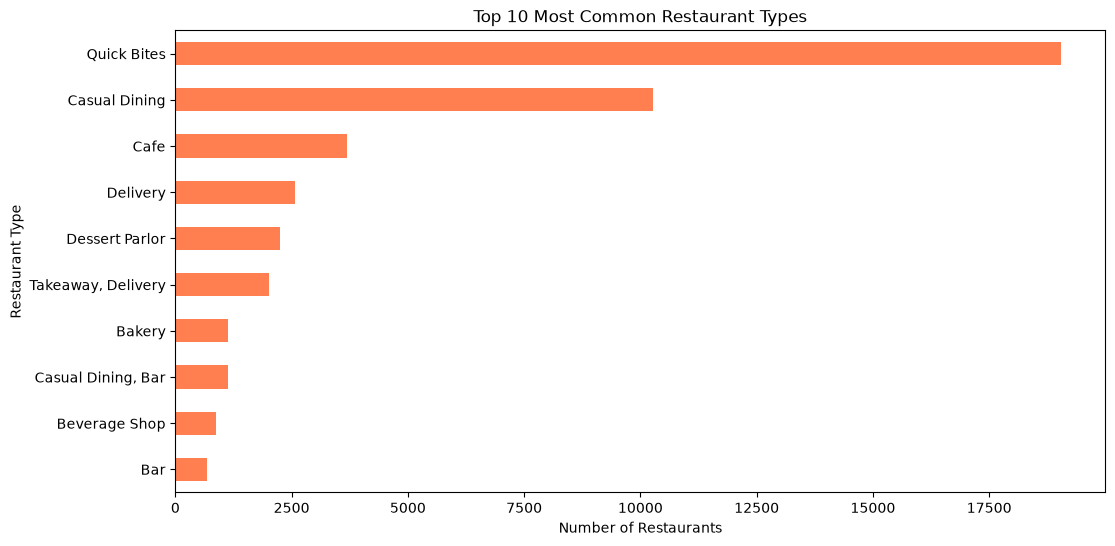

In [78]:
plt.figure(figsize=(12,6))

rest_type_count.head(10).sort_values().plot(
    kind='barh',
    color='coral'
)

plt.title('Top 10 Most Common Restaurant Types')
plt.xlabel('Number of Restaurants')
plt.ylabel('Restaurant Type')

plt.show()

In [79]:
# Votes Analysis

In [80]:
top_voted = df_clean.nlargest(10, 'votes')

print(top_voted[['name', 'location', 'rate', 'votes']])

                              name               location  rate  votes
49170  Byg Brewski Brewing Company          Sarjapur Road   4.9  16832
49627  Byg Brewski Brewing Company          Sarjapur Road   4.9  16832
50059  Byg Brewski Brewing Company          Sarjapur Road   4.9  16832
3921   Byg Brewski Brewing Company          Sarjapur Road   4.9  16345
4801   Byg Brewski Brewing Company          Sarjapur Road   4.9  16345
4944   Byg Brewski Brewing Company          Sarjapur Road   4.9  16345
18643                         Toit            Indiranagar   4.7  14956
19268                         Toit            Indiranagar   4.7  14956
36668                     Truffles  Koramangala 5th Block   4.7  14726
33913                     Truffles  Koramangala 5th Block   4.7  14723


In [81]:
top_unique = (
    df_clean.groupby(['name', 'location'])
    .agg(
        rating=('rate', 'max'),
        total_votes=('votes', 'max')
    )
    .sort_values('total_votes', ascending=False)
    .head(10)
)

print(top_unique)

                                                   rating  total_votes
name                        location                                  
Byg Brewski Brewing Company Sarjapur Road             4.9        16832
Toit                        Indiranagar               4.7        14956
Truffles                    Koramangala 5th Block     4.7        14726
AB's - Absolute Barbecues   Marathahalli              4.8        12121
The Black Pearl             Koramangala 5th Block     4.7        10550
Big Pitcher                 Old Airport Road          4.7         9300
Onesta                      Koramangala 4th Block     4.4         9085
Arbor Brewing Company       Brigade Road              4.5         8419
Empire Restaurant           Indiranagar               4.2         8304
Prost Brew Pub              Koramangala 4th Block     4.5         7871


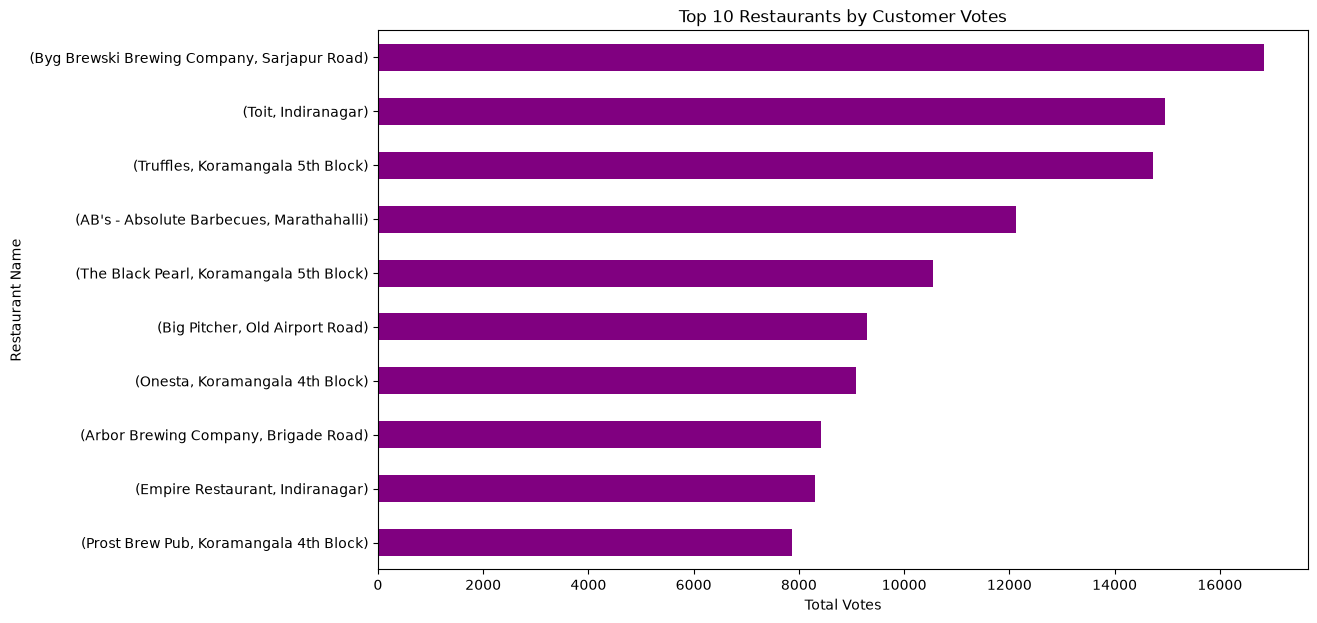

In [83]:
plt.figure(figsize=(12,7))

top_unique['total_votes'].sort_values().plot(
    kind='barh',
    color='purple'
)

plt.title('Top 10 Restaurants by Customer Votes')
plt.xlabel('Total Votes')
plt.ylabel('Restaurant Name')

plt.show()

In [84]:
vote_rating_corr = df_clean[['votes', 'rate']].corr()

print(vote_rating_corr)

          votes      rate
votes  1.000000  0.435256
rate   0.435256  1.000000


In [85]:
# Cost vs Rating

In [86]:
cost_rating = df_clean.groupby('cost_category')['rate'].mean()

print(cost_rating)

cost_category
Budget       3.583963
Expensive    4.129601
Mid-range    3.761332
Name: rate, dtype: float64


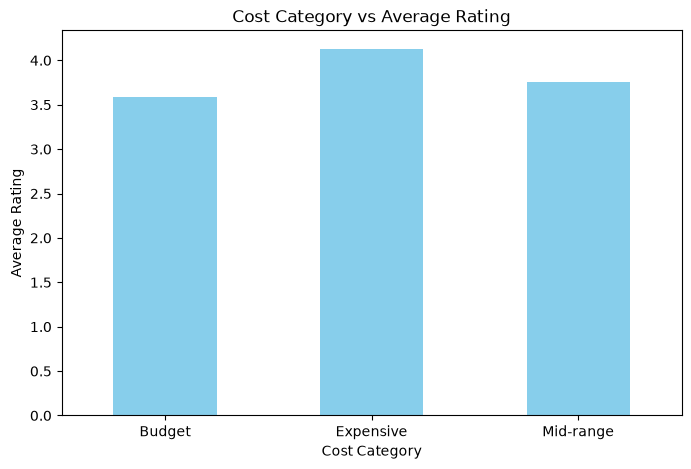

In [87]:
plt.figure(figsize=(8,5))

cost_rating.plot(
    kind='bar',
    color='skyblue'
)

plt.title('Cost Category vs Average Rating')
plt.xlabel('Cost Category')
plt.ylabel('Average Rating')
plt.xticks(rotation=0)

plt.show()

In [88]:
cost_analysis = df_clean.groupby('cost_category').agg(
    restaurant_count=('name', 'count'),
    average_rating=('rate', 'mean'),
    median_rating=('rate', 'median')
)

print(cost_analysis)

               restaurant_count  average_rating  median_rating
cost_category                                                 
Budget                    33106        3.583963            3.6
Expensive                  5280        4.129601            4.2
Mid-range                 12762        3.761332            3.8


# Original vs Cleaned Dataset

In [89]:
print("Original Dataset Shape:", df.shape)
print("Cleaned Dataset Shape:", df_clean.shape)

print("Rows Removed:", df.shape[0] - df_clean.shape[0])
print("Columns Removed:", df.shape[1] - df_clean.shape[1])

Original Dataset Shape: (51717, 17)
Cleaned Dataset Shape: (51148, 14)
Rows Removed: 569
Columns Removed: 3


In [90]:
print(df_clean.isnull().sum())

name                              0
online_order                      0
book_table                        0
rate                           9885
votes                             0
location                          0
rest_type                         0
cuisines                          0
approx_cost(for two people)       0
reviews_list                      0
menu_item                         0
listed_in(type)                   0
listed_in(city)                   0
cost_category                     0
dtype: int64


# ### Data Cleaning Summary

- Removed unnecessary columns: `url`, `address`, `phone`, and `dish_liked`.
- Removed 569 rows containing missing values in important columns.
- Converted restaurant ratings into numeric format.
- Replaced `NEW` and `-` ratings with missing values.
- Converted approximate cost into numeric format.
- Created a new feature: `cost_category`.
- Final dataset contains **51,148 rows and 14 columns**.
- All columns are free from missing values except `rate`, which has 9,885 missing values.

**Conclusion:** The dataset is now cleaned and ready for Exploratory Data Analysis (EDA).

# 7. Business Insights

### 1. Online Ordering Trend

Around 59.26% of restaurants provide online ordering facilities, while 40.74% do not.

**Business Insight:** Online ordering is an important service in the Bangalore restaurant market. Restaurants without online ordering may explore this facility to reach more customers.

### 2. Table Booking Trend

Only 12.61% of restaurants provide table booking facilities, while 87.39% do not.

**Business Insight:** Table booking is less common among the listed restaurants. Restaurants may consider offering advance booking to improve customer convenience.

### 3. Cost vs Average Rating

Expensive restaurants have the highest average rating of 4.13, followed by mid-range restaurants at 3.76 and budget restaurants at 3.58.

**Business Insight:** In this dataset, higher-priced restaurants tend to have higher customer ratings. However, this does not prove that higher prices cause better ratings.

### 4. Most Popular Cuisines

North Indian cuisine is the most frequently listed cuisine with 20,841 appearances, followed by Chinese cuisine with 15,368 appearances.

**Business Insight:** North Indian and Chinese cuisines have a strong presence in the Bangalore restaurant market. New restaurant businesses may consider these cuisines while studying customer demand.

### 5. Restaurant Distribution by Location

BTM has the highest number of restaurant listings (5,071), followed by HSR (2,496) and Koramangala 5th Block (2,481).

**Business Insight:** BTM has a strong restaurant presence in this dataset. Businesses can study restaurant density and competition before choosing a location.

### 6. Table Booking vs Customer Rating

Restaurants offering table booking have an average rating of 4.14, compared to 3.62 for restaurants without table booking.

**Business Insight:** Restaurants offering table booking tend to have higher customer ratings in this dataset. This may indicate an association between booking facilities and customer experience, but it does not establish causation.

### 7. Votes vs Customer Rating

The correlation between votes and restaurant ratings is approximately 0.435, indicating a moderate positive relationship.

**Business Insight:** Restaurants receiving more customer votes tend to have somewhat higher ratings. Customer engagement and restaurant popularity may be associated with better ratings.